# Derm1M: learn from more images without longer fast-mode epochs

Derm1M reports over one million **image–text pairs**, not one million independent
photographs. The local manifests contain 413,210 training rows and 9,806 official
held-out rows. After cleaning and selecting the agreed 20 diagnoses, the current
split has 36,777 training images and 9,195 internal validation images.

Fast mode now cycles through the training pool, using up to **300 images per class
per epoch**. Validation stays fixed. This tests whether seeing more distinct images
helps the previous model's large training/validation gap. ResNet-18, batch size,
learning rates, regularization, and preprocessing are unchanged for this comparison.

Every code cell has an explanation. Captions, disease descriptions, source names,
and symptom fields are **not input features**: they can reveal the target and may
not exist for a new photo. The official CSV has no diagnosis targets, so it supplies
predictions, not measured test accuracy.

Dataset: [Derm1M](https://huggingface.co/datasets/redlessone/Derm1M).


## 0. Prepare the local notebook before importing libraries

On macOS, `ZMQError: Too many open files` means this notebook process has exhausted
its file/socket handles. Restart the kernel to release handles from the failed run,
then run this cell **before Hugging Face imports or login**. We raise a low soft limit
up to 4,096 when the existing hard limit allows it, and disable the parallel Xet
client on macOS. An already higher limit is left alone. No system-wide settings change.

Colab keeps its default backend. Existing `_done_reddit`/`_done_twitter` markers still
skip successfully extracted archives. Keep the same `DERM1M_IMAGE_ROOT` across reruns.
The current interrupted archive may need to be downloaded again; do not delete the
whole image folder or Hugging Face cache to fix this error.

[Hugging Face download settings](https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables)
are read at import time. [Python resource limits](https://docs.python.org/3/library/resource.html)
apply to the current process.


In [1]:
import os
import sys


def raise_file_limit(minimum=4096):
    # This affects only the current notebook process, never system-wide settings.
    import resource
    soft, hard = resource.getrlimit(resource.RLIMIT_NOFILE)
    target = minimum if hard == resource.RLIM_INFINITY else min(minimum, hard)
    if soft != resource.RLIM_INFINITY and soft < target:
        try:
            resource.setrlimit(resource.RLIMIT_NOFILE, (target, hard))
        except (OSError, ValueError) as error:
            print("Could not raise the notebook file limit:", error)
    current = resource.getrlimit(resource.RLIMIT_NOFILE)[0]
    print("Notebook open-file limit:", current)
    return current


if sys.platform == "darwin":
    # Set this BEFORE importing huggingface_hub, including imports used for login.
    os.environ["HF_HUB_DISABLE_XET"] = "1"
    raise_file_limit()
    loaded_constants = sys.modules.get("huggingface_hub.constants")
    if loaded_constants is not None and not loaded_constants.HF_HUB_DISABLE_XET:
        raise RuntimeError("Restart the notebook kernel, then run this setup cell first. "
                           "Hugging Face was imported before the download settings took effect.")
    print("macOS: using HTTP downloads instead of the parallel Xet client.")
else:
    print("Using the default download backend (including in Colab).")


Notebook open-file limit: 1048575
macOS: using HTTP downloads instead of the parallel Xet client.


## 1. Import the libraries

These libraries read tables, open images, build the neural network, and calculate
scores. Install `requirements.txt` in your notebook's Python environment first.

In [ ]:
import hashlib
import io
import json
import os
import random
import re
import shutil
import stat
import time
import zipfile
from pathlib import Path
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import hf_hub_download
from IPython.display import display
from PIL import Image, ImageOps, ImageCms
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18
from tqdm.auto import tqdm


## 2. Choose a focused experiment

Keep the agreed 20 diagnosis labels and batch size 32. `FAST_MODE=True` uses at most
6,000 training and 1,000 validation images per epoch. `ROTATE_TRAINING_IMAGES=True`
moves through the full training pool each epoch; it does not shuffle validation.
Set rotation to False to repeat the original fixed-sample experiment, or set
`FAST_MODE=False` to use every training/validation image each epoch.

Results go to `student_v5_rotating_20/`, preserving the previous run. Use a separate
folder for each comparison. The already measured feature baseline and official
predictions default to off while tuning. Keep early stopping; more epochs are not
an automatic improvement. CUDA uses two workers and mixed precision.


In [ ]:
project = Path.cwd()
if project.name == "model":
    project = project.parent
project = Path(os.getenv("DERM1M_PROJECT", project)).expanduser().resolve()
image_folder = Path(os.getenv("DERM1M_IMAGE_ROOT", Path.home() / "Derm1M_images")).expanduser()
save_folder = project / "dataset" / "processed" / "student_v5_rotating_20"
save_folder.mkdir(parents=True, exist_ok=True)
IMAGE_AUDIT_CSV = project / "dataset" / "processed" / "color_audit_v1" / "image_color_audit.csv"

# Exact dataset names: no automatic merging of related diagnoses or synonyms.
TARGET_CLASSES = [
    "acne", "basal cell carcinoma", "bullous pemphigoid", "eczema",
    "folliculitis", "herpes zoster", "impetigo", "lichen planus", "melanoma",
    "molluscum contagiosum", "nevus", "pityriasis rosea", "psoriasis", "rosacea",
    "scabies", "cellulitis", "seborrheic keratoses",
    "squamous cell carcinoma", "urticaria", "vitiligo",
]
FAST_MODE = False
ROTATE_TRAINING_IMAGES = True  # New images each epoch, same per-epoch budget.
MAX_TRAIN_IMAGES_PER_CLASS = 300
MAX_VAL_IMAGES_PER_CLASS = 50
MIN_IMAGES = 150
MIN_GROUPS = 50
MIN_SOURCES = 2
MIN_TRAIN_PER_CLASS = 80
MIN_VAL_PER_CLASS = 25
MIN_IMAGE_SIDE = 64
MIN_IMAGE_COVERAGE = 0.95
EXCLUDE_UNCERTAIN_CAPTIONS = True

DOWNLOAD_IMAGES = False
METADATA_ONLY = False
REQUIRE_ALL_IMAGES = True  # Require every candidate image to be readable.
RUN_TRAINING = True
RUN_FEATURE_BASELINE = False  # Already measured; enable for a new first-epoch baseline.
RUN_OFFICIAL_TEST = True  # Enable after choosing the final training setup.
BATCH_SIZE = 32
EPOCHS = 20
WARMUP_EPOCHS = 2
PATIENCE = 3
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
NUM_WORKERS = 2 if device.type == "cuda" else 0
USE_AMP = device.type == "cuda"
print("Using:", device, "| data workers:", NUM_WORKERS, "| mixed precision:", USE_AMP)
print("Requested classes:", len(TARGET_CLASSES))
print("Images:", image_folder)
print("Saved results:", save_folder)
if device.type == "cpu":
    print("CPU selected. In Colab choose Runtime > Change runtime type > GPU before training.")


Using: mps | data workers: 0 | mixed precision: False
Requested classes: 20
Images: /Users/kevinharvey/Derm1M_images
Saved results: /Users/kevinharvey/Desktop/DEPI Project/DermaXRAI/dataset/processed/student_v5_rotating_20


## 3. Read the repository's two CSV files

The pretraining CSV supplies our labeled training examples. The official held-out
CSV supplies our final test images; we do not create another test split.
A local CSV path avoids a download. Otherwise, Hugging Face uses its download cache.
Accept the dataset terms and log in first if access is required.

In [ ]:
train_csv = os.getenv("DERM1M_MANIFEST")
if not train_csv:
    train_csv = hf_hub_download("redlessone/Derm1M", "Derm1M_v2_pretrain.csv", repo_type="dataset")

test_csv = os.getenv("DERM1M_TEST_MANIFEST")
if not test_csv:
    test_csv = hf_hub_download("redlessone/Derm1M", "Derm1M_v2_validation.csv", repo_type="dataset")

raw_train = pd.read_csv(train_csv, low_memory=False)
official_test = pd.read_csv(test_csv, low_memory=False)
if not {"filename", "disease_label", "source"}.issubset(raw_train.columns):
    raise ValueError("The training CSV needs filename, disease_label, and source columns.")
if not {"filename", "source"}.issubset(official_test.columns):
    raise ValueError("The official held-out CSV needs filename and source columns.")
print("Training CSV:", len(raw_train), "rows")
print("Official held-out CSV:", len(official_test), "rows")
print("Official columns:", official_test.columns.tolist())
print("Has diagnosis labels:", "disease_label" in official_test.columns)


Training CSV: 413210 rows
Official held-out CSV: 9806 rows
Official columns: ['filename', 'caption', 'truncated_caption', 'source', 'source_type']
Has diagnosis labels: False


## 4. Optional: download and extract the images

This cell runs only when `DOWNLOAD_IMAGES=True`. It downloads one archive at a time,
checks that files stay inside the image folder, and removes each zip after extraction.
The completion markers let you continue after an interrupted download.
The official final-test images come from `validation_data.zip` in the same repository.

The cell prints when the downloader returns and extraction begins. A 100%
reconstruction bar alone is not confirmation that the archive is ready.


In [ ]:
def download_image_archive(name, root):
    try:
        return Path(hf_hub_download(
            "redlessone/Derm1M", f"{name}.zip", repo_type="dataset",
            local_dir=root / "_zips",
        ))
    except Exception as error:
        if getattr(error, "errno", None) == 24 or "too many open files" in str(error).lower():
            raise RuntimeError("The notebook ran out of file/socket handles. Restart the kernel "
                               "and run the first setup cell before Hugging Face imports or login. "
                               "Keep the existing image folder and completed extraction markers.") from error
        raise

if DOWNLOAD_IMAGES:
    image_folder.mkdir(parents=True, exist_ok=True)
    archives = ["reddit", "twitter", "pubmed", "IIYI", "note", "public", "edu", "youtube", "validation_data"]
    for name in archives:
        marker = image_folder / f"_done_{name}"
        if marker.exists():
            print(name, "already extracted")
            continue
        print(f"Downloading {name}.zip; free disk space: {shutil.disk_usage(image_folder).free / 2**30:.1f} GiB")
        zip_path = download_image_archive(name, image_folder)
        print(f"Download returned: {zip_path.name}. Opening archive for extraction...")
        with zipfile.ZipFile(zip_path) as archive:
            files = [f for f in archive.infolist() if not f.is_dir() and not f.filename.startswith("__MACOSX/")]
            if not files:
                raise ValueError(f"Empty archive: {name}")
            has_folder = all(f.filename.split("/")[0].lower() == name.lower() for f in files)
            destination = image_folder if has_folder else image_folder / name
            needed_space = sum(f.file_size for f in files) + 2_000_000_000
            if shutil.disk_usage(image_folder).free < needed_space:
                raise OSError(f"Not enough disk space to extract {name}.")
            for file in tqdm(files, desc=f"Extracting {name}"):
                target = (destination / file.filename).resolve()
                if (not target.is_relative_to(image_folder.resolve())
                        or "\\" in file.filename or stat.S_ISLNK(file.external_attr >> 16)):
                    raise ValueError("Unsafe archive filename.")
                archive.extract(file, destination)
        marker.touch()
        zip_path.unlink()
else:
    print("Using existing images. No image archives were downloaded.")


Using existing images. No image archives were downloaded.


## 5. Clean labels and define the task

Normalize spaces and case. Reject empty/unknown targets, conflicting targets for
one filename, and rows listing several diagnoses. We do not infer a single answer
from a multi-label caption. Save rejections and a count of every label in
`label_scope.csv`, then clean the full single-label pool before selecting `TARGET_CLASSES`.

Labels such as `irritated seborrheic keratosis (from "sk/isk")` contain annotation
text and are outside this experiment. We do not silently rewrite them into another
disease. `acne` is not automatically merged with `acne vulgaris`. A reviewed medical
label mapping would be a separate improvement.

A conservative caption screen flags explicit differential/uncertain diagnosis wording
and saves those rows in `uncertain_caption_rows.csv`. Exclude them from this
single-label experiment while keeping the original labels for review. This is
a text heuristic, not clinical adjudication, and can exclude valid examples.
Captions are never used as model features or to invent replacement targets.


In [ ]:
def choose_label(text):
    words = []
    for word in str(text).split(","):
        words.append(" ".join(word.lower().split()))
    labels = set(words)
    unknown = {"", "nan", "none", "unknown", "no definitive diagnosis"}
    if len(labels) != 1 or labels.intersection(unknown):
        return None
    return words[0]

data = raw_train[["filename", "disease_label", "source"]].fillna("").copy()
data["filename"] = data.filename.str.strip().str.replace("\\", "/", regex=False)
data["disease_label"] = data.disease_label.astype(str).str.lower().str.split().str.join(" ")
data["label"] = data.disease_label.map(choose_label)
conflicts = data.groupby("filename").disease_label.nunique()
conflicting_files = conflicts[conflicts > 1].index
bad_rows = data.label.isna() | data.filename.eq("") | data.filename.isin(conflicting_files)
data.loc[bad_rows].to_csv(save_folder / "rejected_labels.csv", index=False)
data = data.loc[~bad_rows].drop_duplicates("filename").reset_index(drop=True)
print("Clearly labeled images:", len(data))

def caption_needs_review(text):
    # Conservative text screen for explicitly uncertain or differential diagnoses.
    pattern = r"\b(?:differential diagnos(?:is|es)|differential includes|suspected|possible diagnosis|uncertain diagnosis|rule out)\b"
    return bool(re.search(pattern, str(text), flags=re.IGNORECASE))

if EXCLUDE_UNCERTAIN_CAPTIONS and "caption" in raw_train.columns:
    uncertain = raw_train.caption.fillna("").map(caption_needs_review)
    raw_train.loc[uncertain, ["filename", "disease_label", "caption"]].to_csv(
        save_folder / "uncertain_caption_rows.csv", index=False)
    uncertain_files = set(raw_train.loc[uncertain, "filename"].str.strip().str.replace("\\", "/", regex=False))
    data = data.loc[~data.filename.isin(uncertain_files)].reset_index(drop=True)
    print("Rows flagged by uncertain/differential caption wording:", int(uncertain.sum()))

all_label_counts = data.groupby("label").agg(images=("filename", "size"))
all_label_counts["in_scope"] = all_label_counts.index.isin(TARGET_CLASSES)
all_label_counts.to_csv(save_folder / "label_scope.csv")
print("Single-label candidates across the full dataset:", len(data))
print("In the requested 20-class scope:", int(data.label.isin(TARGET_CLASSES).sum()))


Clearly labeled images: 269287
Rows flagged by uncertain/differential caption wording: 9455
Single-label candidates across the full dataset: 264453
In the requested 20-class scope: 67269


## 6. Identify photos from the same case or source

Pictures from one case, post, video, or paper can look almost identical. We give
those pictures the same group so they stay together. This function uses the filename
and source. It works for both training paths and the official `validation_data` paths.
It reduces leakage risk, but the dataset has no patient IDs to guarantee independence.

In [ ]:
def find_group(filename, source):
    stem = Path(filename).stem
    source = str(source).lower()
    if source == "youtube":
        return "youtube:" + stem.split("_frame_")[0]
    article = re.search(r"PMC\d+", stem, flags=re.IGNORECASE)
    if article:
        return "pubmed:" + article.group().lower()
    for site in ["iiyi", "reddit", "twitter"]:
        if source.startswith(site):
            return site + ":" + stem.split("_")[0]
    if source.startswith("textbook"):
        # Book name followed by the page number, before the crop/image numbers.
        page = re.match(r"(.+?_\d{5})(?:_.*)?$", stem)
        if page:
            return "book:" + page.group(1)
    # Same basename in another folder may be the same original image.
    return "image:" + Path(filename).name

data["group"] = [find_group(f, s) for f, s in zip(data.filename, data.source)]
test_groups = {find_group(f, s) for f, s in zip(official_test.filename, official_test.source)}
related = data.group.isin(test_groups)
data.loc[related].to_csv(save_folder / "training_rows_related_to_official_test.csv", index=False)
data = data.loc[~related].reset_index(drop=True)
print("Training images removed because their group appears in the official set:", int(related.sum()))
print("Remaining training candidates:", len(data))


Training images removed because their group appears in the official set: 77788
Remaining training candidates: 186665


## Read and audit color consistently

Record original pixel mode, ICC profile, EXIF color-space tag, transparency, and
frame count. RGB mode alone does not prove that an image is sRGB. Convert valid
embedded profiles to sRGB, correct orientation, and composite transparency onto
white. Untagged RGB/grayscale images use an explicitly reported sRGB assumption.

Invalid/mismatched profiles, unprofiled CMYK/LAB, high-bit-depth images, and
multiple frames are held for review rather than silently rescaled. All source
files are kept intact. The same reader is used for features and neural-network inputs.


In [ ]:
# Cache ICC transforms so images sharing a profile do not rebuild it every time.
@lru_cache(maxsize=64)
def read_color_profile(profile_bytes):
    profile = ImageCms.getOpenProfile(io.BytesIO(profile_bytes))
    name = ImageCms.getProfileName(profile).strip().replace("\n", " ")
    space = str(profile.profile.xcolor_space).strip()
    return profile, name, space


@lru_cache(maxsize=64)
def srgb_transform(profile_bytes, mode):
    profile, _, _ = read_color_profile(profile_bytes)
    return ImageCms.buildTransformFromOpenProfiles(
        profile, ImageCms.createProfile("sRGB"), mode, "RGB")


def exif_color_space(image):
    exif = image.getexif()
    # ColorSpace normally lives inside the EXIF sub-IFD, not the top-level tags.
    return exif.get_ifd(34665).get(40961, exif.get(40961, ""))


def image_color_info(image):
    profile_bytes = image.info.get("icc_profile", b"")
    info = {"original_mode": image.mode, "format": image.format or "",
            "bands": ",".join(image.getbands()), "has_transparency": (
                "A" in image.getbands() or "transparency" in image.info),
            "frames": getattr(image, "n_frames", 1),
            "icc_present": bool(profile_bytes), "icc_name": "", "icc_space": "",
            "icc_error": "", "exif_color_space": str(exif_color_space(image)),
            "png_gamma": str(image.info.get("gamma", ""))}
    if profile_bytes:
        try:
            _, info["icc_name"], info["icc_space"] = read_color_profile(profile_bytes)
        except (OSError, ValueError, TypeError, ImageCms.PyCMSError) as error:
            info["icc_error"] = str(error)[:200]
    return info


def convert_to_srgb(image):
    # Untagged RGB/grayscale web images are assumed sRGB; that assumption is reported.
    profile_bytes = image.info.get("icc_profile", b"")
    mode = image.mode
    if mode not in {"1", "L", "LA", "P", "RGB", "RGBA", "CMYK", "YCbCr", "LAB"}:
        raise ValueError(f"Color review needed for {mode}: no automatic bit-depth rescaling.")
    alpha = None
    if "A" in image.getbands() or "transparency" in image.info:
        rgba = image.convert("RGBA")
        alpha = rgba.getchannel("A")
    color_image = rgba if alpha is not None else image
    if profile_bytes:
        profile, _, space = read_color_profile(profile_bytes)
        if space == "RGB" and mode not in {"CMYK", "LAB"}:
            color = color_image.convert("RGB")
        elif space == "GRAY" and mode in {"1", "L", "LA"}:
            color = image.convert("L")
        elif space == "CMYK" and mode == "CMYK":
            color = image
        elif space == "Lab" and mode == "LAB":
            color = image
        else:
            raise ValueError(f"Color review needed: ICC space {space} does not match mode {mode}.")
        rgb = ImageCms.applyTransform(color, srgb_transform(profile_bytes, color.mode))
        action = "icc_to_srgb"
    else:
        if mode in {"CMYK", "LAB"}:
            raise ValueError(f"Color review needed: {mode} image has no ICC profile.")
        if exif_color_space(image) == 2:
            raise ValueError("Color review needed: Adobe RGB EXIF tag without an ICC profile.")
        rgb = color_image.convert("RGB")
        action = "assumed_srgb"
    if alpha is not None:
        rgb = Image.composite(rgb, Image.new("RGB", rgb.size, "white"), alpha)
        action += "+white_alpha"
    # Returned pixel values follow the target policy; originals are never rewritten.
    rgb.info.pop("transparency", None)
    return rgb, action


def load_rgb(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image)
        rgb, _ = convert_to_srgb(image)
        return rgb


def inspect_image(filename, root):
    path = (root / filename).resolve()
    if not path.is_relative_to(root.resolve()):
        raise ValueError(f"Image path leaves the image folder: {filename}")
    record = {"filename": filename, "status": "ok", "error": "", "file_hash": "",
              "pixel_hash": "", "width": 0, "height": 0, "contrast": 0.0,
              "original_mode": "", "format": "", "bands": "", "has_transparency": False,
              "frames": 0, "icc_present": False, "icc_name": "", "icc_space": "",
              "icc_error": "", "exif_color_space": "", "png_gamma": "", "color_action": "",
              "file_bytes": 0, "modified_ns": 0, "policy_version": "srgb_v2"}
    try:
        file_stat = path.stat()
        record.update(file_bytes=file_stat.st_size, modified_ns=file_stat.st_mtime_ns)
        with Image.open(path) as original:
            record.update(image_color_info(original))
            original.load()  # Fully decode, so truncated/corrupt images are caught.
            oriented = ImageOps.exif_transpose(original)
            record["width"], record["height"] = oriented.size
            if record["frames"] != 1:
                record.update(status="color_review", error="Multiple frames: select a still image explicitly.")
                return record
            try:
                image, record["color_action"] = convert_to_srgb(oriented)
            except (OSError, ValueError, TypeError, ImageCms.PyCMSError) as error:
                record.update(status="color_review", error=str(error)[:300])
                return record
            record["pixel_hash"] = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()
            gray = np.asarray(image.resize((64, 64)).convert("L"), dtype=np.float32)
            record["contrast"] = float(gray.std())
        with path.open("rb") as file:
            record["file_hash"] = hashlib.file_digest(file, "sha256").hexdigest()
    except (OSError, ValueError, TypeError, AttributeError, SyntaxError, Image.DecompressionBombError) as error:
        record.update(status=type(error).__name__, error=str(error)[:300])
    return record


## 7. Audit coverage and image quality

Record readable/missing files, dimensions, contrast, and two fingerprints. A pixel
fingerprint also catches identical displayed images stored with different metadata.
This is not a near-duplicate detector: recompressed/cropped copies may still remain.

Require at least 95% readable candidate images **for every requested class**. Print
and save coverage by class and source. This catches the earlier local run that had
186,456 missing images and only 4,000 readable candidates across the old scope.
That local run is separate from the Colab screenshot.

Official rows are preserved even when an image cannot be read. Missing official
images mean the pixel-based leakage check is incomplete, which is stated explicitly.

The standalone full audit covers every extracted image, including out-of-scope
and unlabeled images. If its CSV exists locally, this cell reuses records whose
file size, modification time, and color-policy version still match. Otherwise
it checks the full single-label candidate pool plus the official set.


In [ ]:
def check_images(rows, root, cache=None):
    results = []
    for filename in tqdm(rows.filename, desc="Checking images/color"):
        path = (root / filename).resolve()
        if not path.is_relative_to(root.resolve()):
            raise ValueError(f"Image path leaves the image folder: {filename}")
        record = None
        if cache is not None and filename in cache.index and path.is_file():
            saved = cache.loc[filename]
            file_stat = path.stat()
            if (saved.policy_version == "srgb_v2" and saved.file_bytes == file_stat.st_size
                    and saved.modified_ns == file_stat.st_mtime_ns):
                record = saved.to_dict()
                record["filename"] = filename
        results.append(record if record is not None else inspect_image(filename, root))
    return pd.DataFrame(results)


def check_coverage(rows, checks, minimum, require_all=False):
    available = rows[["filename", "label", "source"]].merge(checks, on="filename", validate="one_to_one")
    available["readable"] = available.status.eq("ok")
    coverage = available.groupby("label").agg(expected=("filename", "size"), readable=("readable", "sum"))
    coverage["fraction"] = coverage.readable / coverage.expected
    coverage.to_csv(save_folder / "image_coverage_by_class.csv")
    pd.crosstab(available.source, available.status).to_csv(save_folder / "image_coverage_by_source.csv")
    display(coverage)
    bad = coverage.index[coverage.fraction < minimum].tolist()
    if bad or (require_all and not available.readable.all()):
        raise ValueError("Image coverage is too low. Extract the missing archives; do not lower the "
                         f"class thresholds to hide an incomplete download. Affected classes: {bad}")
    return coverage

if not METADATA_ONLY:
    audit_cache = None
    if IMAGE_AUDIT_CSV.is_file():
        audit_cache = pd.read_csv(IMAGE_AUDIT_CSV, keep_default_na=False).set_index("filename")
        print("Reusing the full image/color audit; changed files are inspected again.")
    train_checks = check_images(data, image_folder, audit_cache)
    test_checks = check_images(official_test, image_folder, audit_cache)
    train_checks.to_csv(save_folder / "train_image_checks.csv", index=False)
    test_checks.to_csv(save_folder / "official_test_image_checks.csv", index=False)
    coverage = check_coverage(data.loc[data.label.isin(TARGET_CLASSES)], train_checks, MIN_IMAGE_COVERAGE, REQUIRE_ALL_IMAGES)
    official_missing = int(test_checks.status.ne("ok").sum())
    if official_missing:
        print(f"{official_missing} official images not usable under the color policy: pixel duplicate checks against them are incomplete.")
else:
    print("Metadata only: no images checked. Training and predictions are disabled.")


Reusing the full image/color audit; changed files are inspected again.


Checking images/color:   0%|          | 0/186665 [00:00<?, ?it/s]

Checking images/color:   0%|          | 0/9806 [00:00<?, ?it/s]

,expected,readable,fraction
label,,,
acne,1599,1599,1.0
basal cell carcinoma,2531,2531,1.0
bullous pemphigoid,679,679,1.0
cellulitis,589,589,1.0
eczema,5192,5192,1.0
folliculitis,906,906,1.0
herpes zoster,1450,1450,1.0
impetigo,730,730,1.0
lichen planus,1349,1349,1.0


## 8. Keep useful unique images

Remove unreadable images and images below 64 pixels on the shorter side. Remove all
copies when identical displayed pixels have conflicting labels, and all training
copies of readable official held-out images. For repeated copies with the **same**
label, keep one representative instead of throwing away all of them.

Low-contrast images are flagged for inspection; we do not automatically remove
photos based on brightness, skin tone, or estimated blur. Existing case/source groups
still keep related images together across splits.

Duplicate-label conflicts are checked across the full single-label pool before
restricting training to the selected 20 diagnoses. Color-review cases are also
excluded until their profiles can be interpreted reliably.


In [ ]:
def clean_training_images(rows, train_checks, test_checks, minimum_side):
    checked = rows.merge(train_checks, on="filename", validate="one_to_one")
    checked["removal_reason"] = ""
    checked.loc[checked.status.ne("ok"), "removal_reason"] = "unreadable"
    checked.loc[checked.status.eq("color_review"), "removal_reason"] = "color_review"
    small = checked.status.eq("ok") & (checked[["width", "height"]].min(axis=1) < minimum_side)
    checked.loc[small, "removal_reason"] = "too_small"
    usable = checked.removal_reason.eq("")
    label_counts = checked.loc[usable].groupby("pixel_hash").label.nunique()
    conflicting = set(label_counts.index[label_counts > 1])
    official_hashes = set(test_checks.loc[test_checks.status.eq("ok"), "pixel_hash"]) - {""}
    checked.loc[usable & checked.pixel_hash.isin(conflicting), "removal_reason"] = "conflicting_pixel_labels"
    checked.loc[usable & checked.pixel_hash.isin(official_hashes), "removal_reason"] = "copy_of_official"
    usable = checked.removal_reason.eq("")
    duplicates = checked.loc[usable].sort_values("filename").pixel_hash.duplicated()
    checked.loc[duplicates.index[duplicates], "removal_reason"] = "duplicate_same_label"
    removed = checked.loc[checked.removal_reason.ne("")].copy()
    kept = checked.loc[checked.removal_reason.eq("")].drop(columns="removal_reason").reset_index(drop=True)
    return kept, removed

if not METADATA_ONLY:
    data, removed = clean_training_images(data, train_checks, test_checks, MIN_IMAGE_SIDE)
    removed.to_csv(save_folder / "removed_training_images.csv", index=False)
    print("Removed images:")
    print(removed.removal_reason.value_counts())
    # Flag low contrast for human review, rather than deleting by skin color/brightness.
    data.loc[data.contrast < 5].to_csv(save_folder / "low_contrast_review.csv", index=False)
print("Training candidates left:", len(data))


Removed images:
removal_reason
conflicting_pixel_labels    1142
duplicate_same_label         923
too_small                    764
copy_of_official             171
Name: count, dtype: int64
Training candidates left: 183665


## 9. Require support for every chosen class

Every selected label needs 150 unique images, 50 separate groups, and two sources
before splitting. These modest minimums help avoid learning a class from one video
or source. We also check the actual training and validation counts after splitting.
Having multiple sources reduces one obvious confound but does not prove label quality.


In [ ]:
class_counts = data.groupby("label").agg(images=("filename", "size"), groups=("group", "nunique"),
                                         sources=("source", "nunique"))
class_counts = class_counts.reindex(sorted(TARGET_CLASSES)).fillna(0).astype(int)
class_counts["included"] = ((class_counts.images >= MIN_IMAGES) & (class_counts.groups >= MIN_GROUPS)
                            & (class_counts.sources >= MIN_SOURCES))
class_counts.to_csv(save_folder / "class_counts.csv")
display(class_counts)
unsupported = class_counts.index[~class_counts.included].tolist()
if unsupported:
    raise ValueError(f"Requested classes lack image/group/source support: {unsupported}. "
                     "Check archives and review the class list before training.")
class_names = sorted(TARGET_CLASSES)
if len(class_names) < 2 or len(class_names) != len(set(class_names)):
    raise ValueError("Choose at least two distinct target classes.")
data = data.loc[data.label.isin(class_names)].reset_index(drop=True)
class_to_number = {name: number for number, name in enumerate(class_names)}
print("Supported individual classes:", len(class_names))


,images,groups,sources,included
label,,,,
acne,1593,852,10,True
basal cell carcinoma,2505,1875,11,True
bullous pemphigoid,655,383,9,True
cellulitis,582,352,10,True
eczema,5035,3680,10,True
folliculitis,893,616,10,True
herpes zoster,1425,761,10,True
impetigo,721,400,10,True
lichen planus,1335,674,9,True


Supported individual classes: 20


## 10. Split by group, then cycle through training images

Make the 80/20 group split **before** sampling and save `train_full.csv` and
`val_full.csv`. The seed, class list, cleaning, and validation sample stay unchanged.
Each class has a reproducible shuffled queue, with first images from each group
before second images. Each fast epoch takes the next 300 entries, wrapping around
when needed. An image never appears twice within an epoch. Small classes will repeat
sooner; the output reports how many epochs would cover the largest class.

`train.csv` is the first-epoch sample. During training, save every actual sample in
`epoch_manifests/` and cumulative per-class coverage in `training_coverage.csv`.
Sampling rotation affects only training. The full validation report remains internal
validation, because its fixed sample also selects the best checkpoint.


In [ ]:
def sample_per_class(rows, limit, seed, diverse_groups=False, epoch=0):
    if not isinstance(epoch, int) or isinstance(epoch, bool) or epoch < 0:
        raise ValueError("epoch must be a non-negative integer.")
    if limit is None:
        return rows.copy()
    if not isinstance(limit, int) or isinstance(limit, bool) or limit < 1:
        raise ValueError("Each per-class limit must be a positive integer or None.")
    pieces = []
    for _, group in rows.groupby("label", sort=True):
        shuffled = group.sample(frac=1, random_state=seed)
        if diverse_groups:
            # First take one image per group, then second images, then third, etc.
            shuffled = shuffled.assign(_round=shuffled.groupby("group").cumcount())
            shuffled = shuffled.sort_values("_round", kind="stable").drop(columns="_round")
        # Move along a fixed queue. Every image is reached before the queue wraps.
        # Small classes reuse images across epochs, never within the same epoch.
        count = min(limit, len(shuffled))
        positions = (epoch * count + np.arange(count)) % len(shuffled)
        pieces.append(shuffled.iloc[positions])
    return pd.concat(pieces).sample(frac=1, random_state=seed + epoch).reset_index(drop=True)

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_index, val_index = next(splitter.split(data, data.label, data.group))
train_df = data.iloc[train_index].copy()
val_df = data.iloc[val_index].copy()
if set(train_df.label) != set(class_names) or set(val_df.label) != set(class_names):
    raise ValueError("A class is missing from train/validation. Review its group support.")
if set(train_df.group) & set(val_df.group):
    raise ValueError("A group appears in both training and validation.")
if not METADATA_ONLY and set(train_df.pixel_hash) & set(val_df.pixel_hash):
    raise ValueError("An identical displayed image appears in both training and validation.")
if set(data.group) & test_groups:
    raise ValueError("A training/validation group also appears in the official set.")
full_train_df = train_df.copy()
full_train_df.to_csv(save_folder / "train_full.csv", index=False)
full_train_count = len(full_train_df)
full_val_df = val_df.copy()
full_val_df.to_csv(save_folder / "val_full.csv", index=False)
if FAST_MODE:
    train_df = sample_per_class(train_df, MAX_TRAIN_IMAGES_PER_CLASS, SEED, diverse_groups=True)
    val_df = sample_per_class(val_df, MAX_VAL_IMAGES_PER_CLASS, SEED)
support = pd.DataFrame({"train": train_df.label.value_counts(),
                        "train_groups": train_df.groupby("label").group.nunique(),
                        "full_train": full_train_df.label.value_counts(),
                        "epoch_val": val_df.label.value_counts(),
                        "full_val": full_val_df.label.value_counts()}).reindex(class_names)
support.to_csv(save_folder / "split_support.csv")
display(support)
if (support.train < MIN_TRAIN_PER_CLASS).any() or (support.epoch_val < MIN_VAL_PER_CLASS).any():
    raise ValueError("Too few examples after splitting. Review class support or increase the caps.")
train_df.to_csv(save_folder / "train.csv", index=False)
val_df.to_csv(save_folder / "val.csv", index=False)
official_test.to_csv(save_folder / "official_test.csv", index=False)
pd.crosstab(train_df.label, train_df.source).to_csv(save_folder / "training_sources.csv")
settings = {"classes": class_names, "seed": SEED, "images_checked": not METADATA_ONLY,
            "training_csv": str(train_csv), "official_test_csv": str(test_csv),
            "test_source": "Derm1M_v2_validation.csv", "min_images": MIN_IMAGES, "min_groups": MIN_GROUPS,
            "fast_mode": FAST_MODE,
            "rotate_training_images": FAST_MODE and ROTATE_TRAINING_IMAGES,
            "sampling": "group_ordered_cyclic_v1" if FAST_MODE and ROTATE_TRAINING_IMAGES else "fixed",
            "max_train_images_per_class": MAX_TRAIN_IMAGES_PER_CLASS if FAST_MODE else None,
            "max_val_images_per_class": MAX_VAL_IMAGES_PER_CLASS if FAST_MODE else None,
            "full_train_images": full_train_count, "train_images": len(train_df),
            "epoch_val_images": len(val_df), "full_val_images": len(full_val_df),
            "preprocessing": "letterbox_srgb_v2", "fine_tune": "layer4_and_fc",
            "exclude_uncertain_captions": EXCLUDE_UNCERTAIN_CAPTIONS,
            "min_image_coverage": MIN_IMAGE_COVERAGE, "min_image_side": MIN_IMAGE_SIDE,
            "min_sources": MIN_SOURCES, "batch_size": BATCH_SIZE, "epochs": EPOCHS}
with (save_folder / "settings.json").open("w") as file:
    json.dump(settings, file, indent=2)
print(f"Training images per epoch: {len(train_df):,} / {full_train_count:,}")
print(f"Validation images per epoch: {len(val_df):,} / {len(full_val_df):,}")
print("Full internal validation is evaluated once after training.")
print("Official final input rows:", len(official_test))
if FAST_MODE and ROTATE_TRAINING_IMAGES:
    coverage_epochs = int(np.ceil(support.full_train / support.train).max())
    print(f"Rotating training images: {coverage_epochs} epochs would visit every training image.")
    print("Early stopping may stop sooner; actual coverage is saved each epoch.")


,train,train_groups,full_train,epoch_val,full_val
label,,,,,
acne,300,300,1274,50,319
basal cell carcinoma,300,300,2004,50,501
bullous pemphigoid,300,300,524,50,131
cellulitis,300,278,465,50,117
eczema,300,300,4028,50,1007
folliculitis,300,300,715,50,178
herpes zoster,300,300,1140,50,285
impetigo,300,300,577,50,144
lichen planus,300,300,1068,50,267


Training images per epoch: 6,000 / 36,777
Validation images per epoch: 1,000 / 9,195
Full internal validation is evaluated once after training.
Official final input rows: 9806
Rotating training images: 26 epochs would visit every training image.
Early stopping may stop sooner; actual coverage is saved each epoch.


## 11. Preserve image content and use mild augmentation

Fit the whole image into a square with padding instead of randomly cropping away
part of the condition. Keep the pretrained model's normalization. Training alone
gets flips, small rotations, and mild brightness/contrast variation. Validation and
predictions use the same deterministic preprocessing saved with the checkpoint.

We avoid automatic whitening, strong hue changes, and histogram equalization because
these change color information. The preview below lets you inspect the result.
References: [Pillow ImageOps](https://pillow.readthedocs.io/en/stable/reference/ImageOps.html),
[Torchvision ResNet-18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).


In [ ]:
pretrained_weights = ResNet18_Weights.DEFAULT
IMAGE_MEAN = (0.485, 0.456, 0.406)
IMAGE_STD = (0.229, 0.224, 0.225)


def resize_and_pad(image):
    # Fit the entire image into 224x224, keeping the aspect ratio.
    return ImageOps.pad(image, (224, 224), method=Image.Resampling.BILINEAR,
                        color=(124, 116, 104))


def checkpoint_transform(checkpoint):
    version = checkpoint.get("preprocessing", "resnet18_default_v1")
    if version == "resnet18_default_v1":
        return ResNet18_Weights.DEFAULT.transforms()  # Previous notebook checkpoints.
    if version not in {"letterbox_rgb_v1", "letterbox_srgb_v2"}:
        raise ValueError(f"Unknown preprocessing: {version}")
    return transforms.Compose([resize_and_pad, transforms.ToTensor(),
                               transforms.Normalize(IMAGE_MEAN, IMAGE_STD)])

train_transform = transforms.Compose([
    # Mild lighting changes; no hue shifts, whitening, or aggressive lesion crops.
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10, interpolation=transforms.InterpolationMode.BILINEAR,
                              expand=True, fill=(124, 116, 104)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    resize_and_pad,
    transforms.ToTensor(),
    transforms.Normalize(IMAGE_MEAN, IMAGE_STD),
])
eval_transform = checkpoint_transform({"preprocessing": "letterbox_srgb_v2"})


## Inspect the selected images

Show one training example per label and save its filename/source. Check whether
these are useful photographs and whether labels appear plausible. A montage does
not validate the dataset; systematic diagnosis review needs qualified annotation.


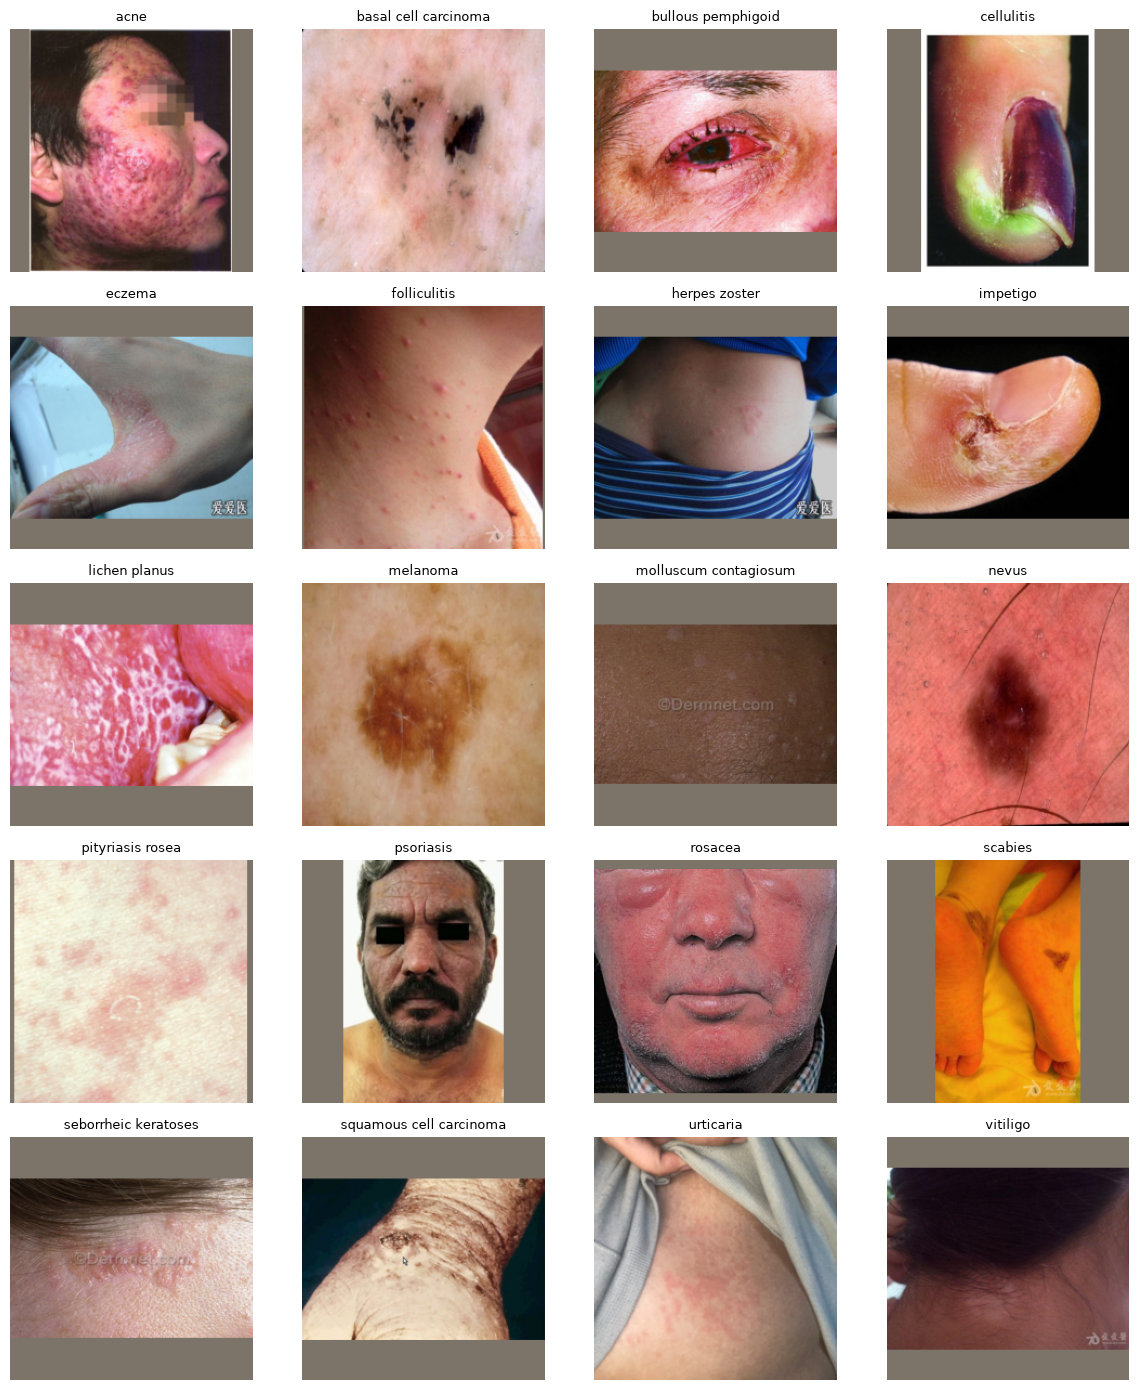

In [ ]:
if not METADATA_ONLY:
    preview_rows = train_df.groupby("label", sort=True).sample(n=1, random_state=SEED)
    preview_rows[["filename", "label", "source"]].to_csv(save_folder / "label_review_samples.csv", index=False)
    fig, axes = plt.subplots(5, 4, figsize=(12, 14))
    for axis in axes.flat:
        axis.axis("off")
    for axis, row in zip(axes.flat, preview_rows.itertuples()):
        axis.imshow(resize_and_pad(load_rgb(image_folder / row.filename)))
        axis.set_title(row.label, fontsize=9)
    plt.tight_layout()
    plt.savefig(save_folder / "training_preview.png", dpi=120)
    plt.show()


## 12. Load the smaller dataset efficiently

Each item is an image and its class number. CUDA uses two workers to decode images
while the GPU trains, with pinned memory for transfers. Set `NUM_WORKERS=0` if your
notebook environment has worker errors. The source files are never rewritten.


In [ ]:
class SkinDataset(Dataset):
    def __init__(self, rows, root, transform):
        self.rows = rows.reset_index(drop=True)
        self.root = root
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        image = self.transform(load_rgb(self.root / row.filename))
        return image, class_to_number[row.label]


def make_loader(rows, transform, shuffle=False, seed=SEED):
    return DataLoader(SkinDataset(rows, image_folder, transform), batch_size=BATCH_SIZE,
                      shuffle=shuffle, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda",
                      persistent_workers=False, generator=torch.Generator().manual_seed(seed))

train_loader = val_loader = full_val_loader = None
if not METADATA_ONLY:
    train_loader = make_loader(train_df, train_transform, shuffle=True)
    val_loader = make_loader(val_df, eval_transform)
    full_val_loader = make_loader(full_val_df, eval_transform)
    print("Training batches:", len(train_loader), "Validation batches:", len(val_loader))


Training batches: 188 Validation batches: 32


## Test simple feature engineering

Extract RGB averages/spread, brightness/spread, saturation/spread, and horizontal/
vertical edge strength. These 12 easy-to-understand features describe global color
and texture, including background; they are not lesion segmentation or diagnostic rules.

Train a small logistic-regression baseline on the **first-epoch training images** and score
it on the **same validation sample** as the CNN. Standardization is learned from
training only. The CNN sees additional images when rotation is enabled. This tests how useful simple engineered features are before adding
complexity to the neural network. ResNet separately learns richer visual features;
we do not assume concatenating these global statistics will improve it.

Run this once; set `RUN_FEATURE_BASELINE=False` to skip it later.
[Scikit-learn pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html).


In [ ]:
def image_features(image):
    # Twelve features, calculated from image pixels only, before square padding.
    rgb = np.asarray(image.resize((64, 64)), dtype=np.float32) / 255.0
    gray = 0.299 * rgb[:, :, 0] + 0.587 * rgb[:, :, 1] + 0.114 * rgb[:, :, 2]
    highest, lowest = rgb.max(axis=2), rgb.min(axis=2)
    saturation = (highest - lowest) / np.maximum(highest, 1e-6)
    return np.concatenate([
        rgb.mean(axis=(0, 1)), rgb.std(axis=(0, 1)),
        [gray.mean(), gray.std(), saturation.mean(), saturation.std(),
         np.abs(np.diff(gray, axis=0)).mean(), np.abs(np.diff(gray, axis=1)).mean()],
    ]).astype(np.float32)


def extract_features(rows):
    return np.stack([image_features(load_rgb(image_folder / name))
                     for name in tqdm(rows.filename, desc="Color/texture features")])

if RUN_FEATURE_BASELINE and not METADATA_ONLY:
    train_features = extract_features(train_df)
    val_features = extract_features(val_df)
    # Scaling is fitted on training data only; validation never fits the pipeline.
    feature_model = make_pipeline(StandardScaler(),
                                  LogisticRegression(max_iter=1000, class_weight="balanced"))
    feature_model.fit(train_features, train_df.label)
    feature_predictions = feature_model.predict(val_features)
    feature_metrics = {"val_accuracy": accuracy_score(val_df.label, feature_predictions),
                       "val_macro_f1": f1_score(val_df.label, feature_predictions,
                                               labels=class_names, average="macro", zero_division=0)}
    pd.DataFrame([feature_metrics]).to_csv(save_folder / "feature_baseline_metrics.csv", index=False)
    pd.DataFrame(train_features, columns=[f"feature_{i}" for i in range(12)]).assign(
        filename=train_df.filename.to_numpy(), label=train_df.label.to_numpy()
    ).to_csv(save_folder / "training_image_features.csv", index=False)
    print("Simple color/texture baseline on the same validation sample:", feature_metrics)
else:
    print("Color/texture baseline disabled.")


Color/texture baseline disabled.


## 13. Use transfer learning with a small trainable part

Keep pretrained ResNet-18 and its simple dropout + linear classifier. During the
first two epochs, only the new classifier learns. Then unfreeze **only `layer4`**
(the last feature block) plus the classifier. This limits the number of weights
adapted to a small dataset and reduces backward-pass work. Freeze batch-normalization
running statistics in both phases.

Use mild inverse-square-root class weights calculated from the **selected training
rows**. We do not also oversample classes, which would apply balancing twice.
A larger neural network is not the first fix for incomplete/noisy training data.
[PyTorch transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).


In [ ]:
def make_model(number_of_classes, weights=None):
    network = resnet18(weights=weights)
    network.fc = nn.Sequential(nn.Dropout(0.25), nn.Linear(network.fc.in_features, number_of_classes))
    return network


def set_trainable_layers(network, fine_tune):
    for name, parameter in network.named_parameters():
        parameter.requires_grad = name.startswith("fc.") or (fine_tune and name.startswith("layer4."))


def set_training_mode(network, fine_tune):
    network.eval()  # Frozen early blocks and running batch statistics stay fixed.
    if fine_tune:
        network.layer4.train()
    network.fc.train()
    for layer in network.modules():
        if isinstance(layer, nn.BatchNorm2d):
            layer.eval()

model = None
if not METADATA_ONLY and RUN_TRAINING:
    model = make_model(len(class_names), pretrained_weights).to(device)
    set_trainable_layers(model, fine_tune=False)
    counts = train_df.label.value_counts().reindex(class_names).to_numpy()
    class_weights = np.sqrt(counts.sum() / (len(class_names) * counts))
    class_weights /= class_weights.mean()
    class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)
    loss_function = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(model.fc.parameters(), lr=0.001, weight_decay=0.0001)
    print("Model outputs:", len(class_names))


Model outputs: 20


## 14. Measure generalization and compare with a baseline

Validation runs without changing weights. Record unweighted cross-entropy, accuracy,
and macro F1. Macro F1 gives each class equal importance. Also show what happens
if we always predict the largest training class. This puts the model's accuracy
in context without assuming that 26% is good or bad by itself.


In [ ]:
def evaluate(network, loader):
    network.eval()
    true_labels, predicted_labels = [], []
    total_loss = 0.0
    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                outputs = network(images)
            total_loss += nn.functional.cross_entropy(outputs.float(), labels, reduction="sum").item()
            true_labels.extend(labels.cpu().tolist())
            predicted_labels.extend(outputs.argmax(dim=1).cpu().tolist())
    return true_labels, predicted_labels, total_loss / len(true_labels)


def get_predictions(loader):
    actual, predicted, _ = evaluate(model, loader)
    return actual, predicted

if not METADATA_ONLY:
    majority = train_df.label.value_counts().idxmax()
    majority_predictions = [majority] * len(val_df)
    print("Always predict the largest training class:", majority)
    print("Baseline accuracy:", accuracy_score(val_df.label, majority_predictions))
    print("Baseline macro F1:", f1_score(val_df.label, majority_predictions,
                                       labels=class_names, average="macro", zero_division=0))


Always predict the largest training class: folliculitis
Baseline accuracy: 0.05
Baseline macro F1: 0.0047619047619047615


## 15. Train, time each epoch, and save the best model

Head-only warmup is followed by fine-tuning the last block. CUDA uses automatic
mixed precision; CPU/MPS keep full precision. Gradient clipping limits large updates.
Reduce the learning rate and stop early based on validation macro F1.

Print training accuracy, validation loss/accuracy/F1, number of different classes
predicted, and elapsed seconds. Rising training accuracy with flat validation scores
suggests overfitting; predicting very few classes suggests collapse or imbalance.
Training accuracy includes augmentation and dropout, so it is not directly the same
measurement as validation accuracy. Training loss is weighted; validation loss is not.
Save history every epoch, so interrupted Colab runs keep the completed history.
[PyTorch mixed precision](https://docs.pytorch.org/docs/stable/amp.html).


In [ ]:
model_path = save_folder / "best_skin_model.pth"
history = []
seen_training_files = set()
if not METADATA_ONLY and RUN_TRAINING:
    if not 0 <= WARMUP_EPOCHS < EPOCHS:
        raise ValueError("WARMUP_EPOCHS must be smaller than EPOCHS.")
    print("Epoch metrics use a fixed validation sample:", len(val_df), "images")
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best_f1, epochs_without_improvement = -1.0, 0
    for epoch in range(EPOCHS):
        started = time.perf_counter()
        epoch_rows = train_df
        if FAST_MODE and ROTATE_TRAINING_IMAGES:
            epoch_rows = sample_per_class(full_train_df, MAX_TRAIN_IMAGES_PER_CLASS,
                                          SEED, diverse_groups=True, epoch=epoch)
            train_loader = make_loader(epoch_rows, train_transform, shuffle=True, seed=SEED + epoch)
        # Save the selected manifest; coverage counts only completed epochs.
        epoch_folder = save_folder / "epoch_manifests"
        epoch_folder.mkdir(exist_ok=True)
        epoch_rows[["filename", "label", "group", "source"]].to_csv(
            epoch_folder / f"epoch_{epoch + 1:02d}.csv", index=False)
        new_images = len(set(epoch_rows.filename) - seen_training_files)
        fine_tune = epoch >= WARMUP_EPOCHS
        if epoch == WARMUP_EPOCHS:
            set_trainable_layers(model, fine_tune=True)
            optimizer = torch.optim.AdamW([
                {"params": model.layer4.parameters(), "lr": 0.0001},
                {"params": model.fc.parameters(), "lr": 0.0003},
            ], weight_decay=0.0001)
            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=2)
        set_training_mode(model, fine_tune)
        total_loss, total_weight, train_correct, train_seen = 0.0, 0.0, 0, 0
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}"):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                outputs = model(images)
                loss = loss_function(outputs, labels)
            if not torch.isfinite(loss):
                raise ValueError("Training loss became invalid. Check images and learning rate.")
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            scaler.step(optimizer)
            scaler.update()
            batch_weight = class_weights[labels].sum().item()
            total_loss += loss.item() * batch_weight
            total_weight += batch_weight
            train_correct += (outputs.argmax(dim=1) == labels).sum().item()
            train_seen += len(labels)
        seen_training_files.update(epoch_rows.filename)
        coverage = full_train_df.assign(seen=full_train_df.filename.isin(seen_training_files))
        coverage.groupby("label").agg(available=("filename", "size"), seen=("seen", "sum")).to_csv(
            save_folder / "training_coverage.csv")
        actual, predicted, val_loss = evaluate(model, val_loader)
        accuracy = accuracy_score(actual, predicted)
        macro_f1 = f1_score(actual, predicted, labels=range(len(class_names)), average="macro", zero_division=0)
        seconds = time.perf_counter() - started
        history.append({"epoch": epoch + 1, "train_loss_weighted": total_loss / total_weight,
                        "train_accuracy_augmented": train_correct / train_seen,
                        "val_loss": val_loss, "val_accuracy": accuracy, "val_macro_f1": macro_f1,
                        "predicted_classes": len(set(predicted)), "seconds": seconds,
                        "training_images": len(epoch_rows), "new_training_images": new_images,
                        "unique_training_images_seen": len(seen_training_files),
                        "training_pool_coverage": len(seen_training_files) / len(full_train_df)})
        print(f"Epoch {epoch + 1}: train accuracy={train_correct / train_seen:.3f}, "
              f"val loss={val_loss:.3f}, val accuracy={accuracy:.3f}, macro F1={macro_f1:.3f}, "
              f"predicted classes={len(set(predicted))}/{len(class_names)}, time={seconds:.1f}s")
        print(f"Training coverage: {len(seen_training_files):,}/{len(full_train_df):,} "
              f"distinct images; {new_images:,} new this epoch")
        pd.DataFrame(history).to_csv(save_folder / "training_history.csv", index=False)
        if fine_tune:
            scheduler.step(macro_f1)
        if macro_f1 > best_f1:
            best_f1, epochs_without_improvement = macro_f1, 0
            torch.save({"weights": model.state_dict(), "classes": class_names,
                        "preprocessing": "letterbox_srgb_v2", "settings": settings,
                        "epoch": epoch + 1, "val_macro_f1": float(best_f1)}, model_path)
        elif fine_tune:
            epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print("Early stopping: validation macro F1 has stopped improving.")
            break
else:
    print("Training is disabled.")


Epoch metrics use a fixed validation sample: 1000 images


Epoch 1:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 1: train accuracy=0.167, val loss=2.516, val accuracy=0.221, macro F1=0.199, predicted classes=20/20, time=105.9s
Training coverage: 6,000/36,777 distinct images; 6,000 new this epoch


Epoch 2:   0%|          | 0/188 [00:00<?, ?it/s]

KeyboardInterrupt: 

## 16. Inspect the full internal validation results and mistakes

Reload the checkpoint chosen by sample macro F1, then evaluate the full internal
validation split once. Export per-class scores, all predictions, mistaken examples,
and accuracy by source. Source comparisons may reflect different class mixes; they
are diagnostics rather than proof of a source bias. Plot learning curves and the
confusion matrix. Use the error list for label review and future data collection.

The full internal validation report is **not** an independent final test score,
because part of this split selected the checkpoint. The official set remains separate.


In [ ]:
if not METADATA_ONLY and RUN_TRAINING:
    checkpoint = torch.load(model_path, map_location=device, weights_only=True)
    if checkpoint["classes"] != class_names:
        raise ValueError("The checkpoint uses a different class list.")
    model.load_state_dict(checkpoint["weights"])
    print("Evaluating the full internal validation set:", len(full_val_df), "images")
    actual, predicted, full_val_loss = evaluate(model, full_val_loader)
    predictions_table = full_val_df.reset_index(drop=True).copy()
    predictions_table["predicted_class"] = [class_names[i] for i in predicted]
    predictions_table["correct"] = np.asarray(actual) == np.asarray(predicted)
    predictions_table.to_csv(save_folder / "validation_predictions.csv", index=False)
    predictions_table.loc[~predictions_table.correct].to_csv(save_folder / "validation_errors.csv", index=False)
    source_metrics = []
    for source, rows in predictions_table.groupby("source"):
        source_metrics.append({"source": source, "images": len(rows), "accuracy": rows.correct.mean()})
    pd.DataFrame(source_metrics).to_csv(save_folder / "validation_by_source.csv", index=False)
    # Compare the same diagnosis across sources before blaming a source's class mix.
    predictions_table.groupby(["source", "label"]).agg(
        images=("filename", "size"), recall=("correct", "mean")
    ).to_csv(save_folder / "validation_by_source_and_class.csv")
    print("Best checkpoint epoch:", checkpoint.get("epoch"))
    print("Full validation loss:", full_val_loss)
    class_numbers = list(range(len(class_names)))
    report = classification_report(actual, predicted, labels=class_numbers,
                                   target_names=class_names, output_dict=True, zero_division=0)
    report_table = pd.DataFrame(report).T
    report_table.to_csv(save_folder / "validation_report.csv")
    display(report_table)
    matrix = confusion_matrix(actual, predicted, labels=class_numbers)
    matrix = pd.DataFrame(matrix, index=class_names, columns=class_names)
    matrix.to_csv(save_folder / "validation_confusion_matrix.csv")
    shown = full_val_df.label.value_counts().head(15).index
    import seaborn as sns
    plt.figure(figsize=(10, 8))
    sns.heatmap(matrix.loc[shown, shown], cmap="Blues",annot=True)
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.title("Validation confusion matrix — most common classes shown")
    plt.tight_layout()
    plt.show()

    curves = pd.DataFrame(history)
    if not curves.empty:
        fig, axes = plt.subplots(1, 2, figsize=(10, 3))
        axes[0].plot(curves.epoch, curves.train_accuracy_augmented, label="Train (augmented)")
        axes[0].plot(curves.epoch, curves.val_accuracy, label="Validation sample")
        axes[0].set_title("Accuracy"); axes[0].legend()
        axes[1].plot(curves.epoch, curves.val_macro_f1, label="Validation macro F1")
        axes[1].set_title("Macro F1"); axes[1].legend()
        plt.tight_layout()
        plt.savefig(save_folder / "learning_curves.png", dpi=120)
        plt.show()


## 17. Predict the repository's official held-out images

This is the final test-input step. Enable `RUN_OFFICIAL_TEST` after training choices
are finished. We load the saved model and process only the official CSV's images.
We keep **one output row for every original row, in the same order**. Missing/broken
images get a status. We never replace missing images with training images.

The current official CSV has no diagnosis targets, so this step exports predictions
and probabilities without reporting a made-up accuracy. Probabilities are relative
to the model's known classes; they are not medical confidence.

In [ ]:
if RUN_OFFICIAL_TEST and not METADATA_ONLY:
    checkpoint = torch.load(model_path, map_location=device, weights_only=True)
    saved_classes = checkpoint["classes"]
    test_model = make_model(len(saved_classes))
    predict_transform = checkpoint_transform(checkpoint)
    test_model.load_state_dict(checkpoint["weights"])
    test_model = test_model.to(device).eval()
    predicted_names = []
    predicted_probabilities = []
    with torch.no_grad():
        for row in tqdm(test_checks.itertuples(), total=len(test_checks), desc="Official final predictions"):
            if row.status != "ok":
                predicted_names.append(None)
                predicted_probabilities.append(None)
                continue
            image = predict_transform(load_rgb(image_folder / row.filename)).unsqueeze(0).to(device)
            probabilities = test_model(image).softmax(dim=1)[0]
            probability, number = probabilities.max(dim=0)
            predicted_names.append(saved_classes[number.item()])
            predicted_probabilities.append(probability.item())
    results = official_test.copy()
    results["image_status"] = test_checks.status.to_numpy()
    results["predicted_class"] = predicted_names
    results["probability"] = predicted_probabilities
    results.to_csv(save_folder / "official_test_predictions.csv", index=False)
    print("Official rows preserved:", len(results))
    print("No official-test accuracy: this CSV does not provide diagnosis labels.")
    display(results[["filename", "image_status", "predicted_class", "probability"]].head())
else:
    print("Official predictions disabled. Enable RUN_OFFICIAL_TEST when ready.")


## 18. Optional: predict one new image

Set `PREDICT_IMAGE` to a photo path to see the five most likely individual classes.
The class names are loaded with the model, so their order stays correct.
A class absent from the training labels cannot be recognized as a new category.

In [ ]:
PREDICT_IMAGE = os.getenv("DERM1M_PREDICT_IMAGE", "")
if PREDICT_IMAGE and not METADATA_ONLY:
    checkpoint = torch.load(model_path, map_location=device, weights_only=True)
    saved_classes = checkpoint["classes"]
    prediction_model = make_model(len(saved_classes))
    predict_transform = checkpoint_transform(checkpoint)
    prediction_model.load_state_dict(checkpoint["weights"])
    prediction_model = prediction_model.to(device).eval()
    image = predict_transform(load_rgb(Path(PREDICT_IMAGE).expanduser())).unsqueeze(0).to(device)
    with torch.no_grad():
        probabilities = prediction_model(image).softmax(dim=1)[0]
    values, numbers = probabilities.topk(min(5, len(saved_classes)))
    display(pd.DataFrame({"class": [saved_classes[i] for i in numbers.tolist()],
                          "probability": values.cpu().tolist()}))
else:
    print("Set PREDICT_IMAGE to predict a new photo.")
